<a href="https://colab.research.google.com/github/KeshavSingh32/UCS420/blob/main/KeshavSinghA8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import numpy as np
import re
from sklearn.metrics.pairwise import cosine_similarity
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Embedding, LSTM, Dense
from keras.utils import pad_sequences
from keras.src.legacy.preprocessing.text import Tokenizer# Or use keras.layers.TextVectorization

In [3]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [4]:
text = """
I really like to play basketaball. Its fun to do those fancy stuff like cool layups and dribbling and the fun thing about basketaball
is that if you have a basketaball and you are alone, you can do drills and improve your game. I don't watch NBA regularly and when
I watch its usually highlights. My favourite team is Timberwolves and favourite player is Kyrie Irving. I started playing it when I
was in 11th standard. In college I don't play that often but yeah I want to continue playing it in the future.
"""

In [5]:
#Q1


# 1. Convert to lowercase and remove punctuation

new_text = text.lower()
new_text = re.sub(r'[^\w\s]', '', new_text)

print("Lowercase text without punctuation:\n")
print(new_text)


# 2. Tokenize into sentences and words

sentence_tokens = sent_tokenize(text)
word_tokens = word_tokenize(new_text)

print("\nSentence Tokens:")
print(sentence_tokens)

print("\nWord Tokens:")
print(word_tokens)

# 3. Compare split() and word_tokenize()

split_words = new_text.split()

print("\nUsing split():")
print(split_words)

print("\nUsing word_tokenize():")
print(word_tokens)

print("\nComparison:")
print("Number of words using split():", len(split_words))
print("Number of words using word_tokenize():", len(word_tokens))


# 4. Remove stopwords

stop_words = set(stopwords.words("english"))

filtered_words = [
    word for word in word_tokens
    if word not in stop_words
]

print("\nWords after removing stopwords:")
print(filtered_words)


# 5. Word Frequency Distribution

freq_dist = FreqDist(filtered_words)

print("\nWord Frequency Distribution:")
for word, count in freq_dist.items():
    print(f"{word}: {count}")

Lowercase text without punctuation:


i really like to play basketaball its fun to do those fancy stuff like cool layups and dribbling and the fun thing about basketaball
is that if you have a basketaball and you are alone you can do drills and improve your game i dont watch nba regularly and when
i watch its usually highlights my favourite team is timberwolves and favourite player is kyrie irving i started playing it when i
was in 11th standard in college i dont play that often but yeah i want to continue playing it in the future


Sentence Tokens:
['\nI really like to play basketaball.', 'Its fun to do those fancy stuff like cool layups and dribbling and the fun thing about basketaball\nis that if you have a basketaball and you are alone, you can do drills and improve your game.', "I don't watch NBA regularly and when\nI watch its usually highlights.", 'My favourite team is Timberwolves and favourite player is Kyrie Irving.', 'I started playing it when I\nwas in 11th standard.', "In 

In [8]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [9]:
#Q2

# 1. Extract alphabet-only words

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

print("Alphabet-only words:\n")
print(words)


# 2. Remove stopwords

stop_words = set(stopwords.words("english"))

filtered_words = [
    word for word in words
    if word not in stop_words
]

print("\nWords after removing stopwords:\n")
print(filtered_words)


# 3. Stemming

stemmer = PorterStemmer()

stemmed_words = [
    stemmer.stem(word)
    for word in filtered_words
]

print("\nStemmed Words:\n")
print(stemmed_words)


# 4. Lemmatization

lemmatizer = WordNetLemmatizer()

lemmatized_words = [
    lemmatizer.lemmatize(word)
    for word in filtered_words
]

print("\nLemmatized Words:\n")
print(lemmatized_words)

# 5. Compare Stemming vs Lemmatization

print("\nComparison:\n")
print(f"{'Original':<20}{'Stemmed':<20}{'Lemmatized'}")
print("-" * 60)

for original, stemmed, lemma in zip(filtered_words, stemmed_words, lemmatized_words):
    print(f"{original:<20}{stemmed:<20}{lemma}")

Alphabet-only words:

['i', 'really', 'like', 'to', 'play', 'basketaball', 'its', 'fun', 'to', 'do', 'those', 'fancy', 'stuff', 'like', 'cool', 'layups', 'and', 'dribbling', 'and', 'the', 'fun', 'thing', 'about', 'basketaball', 'is', 'that', 'if', 'you', 'have', 'a', 'basketaball', 'and', 'you', 'are', 'alone', 'you', 'can', 'do', 'drills', 'and', 'improve', 'your', 'game', 'i', 'don', 't', 'watch', 'nba', 'regularly', 'and', 'when', 'i', 'watch', 'its', 'usually', 'highlights', 'my', 'favourite', 'team', 'is', 'timberwolves', 'and', 'favourite', 'player', 'is', 'kyrie', 'irving', 'i', 'started', 'playing', 'it', 'when', 'i', 'was', 'in', 'standard', 'in', 'college', 'i', 'don', 't', 'play', 'that', 'often', 'but', 'yeah', 'i', 'want', 'to', 'continue', 'playing', 'it', 'in', 'the', 'future']

Words after removing stopwords:

['really', 'like', 'play', 'basketaball', 'fun', 'fancy', 'stuff', 'like', 'cool', 'layups', 'dribbling', 'fun', 'thing', 'basketaball', 'basketaball', 'alone', '

In [12]:
#Q3
texts = [
    "Artificial Intelligence is transforming healthcare by improving diagnosis and treatment.",

    "Machine Learning helps computers learn from data and make accurate predictions.",

    "Deep Learning uses neural networks to solve complex problems like image recognition."
]

# ---------------------------------------
# 1. Bag of Words
# ---------------------------------------

count_vectorizer = CountVectorizer()

bow = count_vectorizer.fit_transform(texts)

print("Bag of Words Matrix:\n")
print(bow.toarray())

print("\nFeatures:")
print(count_vectorizer.get_feature_names_out())

# ---------------------------------------
# 2. TF-IDF
# ---------------------------------------

tfidf_vectorizer = TfidfVectorizer()

tfidf = tfidf_vectorizer.fit_transform(texts)

feature_names = tfidf_vectorizer.get_feature_names_out()

print("\nTF-IDF Matrix:\n")
print(tfidf.toarray())

# ---------------------------------------
# 3. Top 3 Keywords
# ---------------------------------------

print("\nTop 3 Keywords for each Text:\n")

for i, text in enumerate(texts):

    tfidf_scores = tfidf[i].toarray().flatten()

    top_indices = np.argsort(tfidf_scores)[::-1][:3]

    print(f"Text {i+1}:")
    print(text)

    for index in top_indices:
        print(f"{feature_names[index]} : {tfidf_scores[index]:.3f}")

    print("-" * 50)

Bag of Words Matrix:

[[0 1 1 1 0 0 0 0 1 0 1 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0]
 [1 1 0 0 0 1 1 0 0 1 0 1 0 0 0 0 1 1 0 1 1 0 0 1 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 1 0 0 0 0 1 0 0 0 0 1 1 0 0 1 1 0 1 1 1 1 0 0 1]]

Features:
['accurate' 'and' 'artificial' 'by' 'complex' 'computers' 'data' 'deep'
 'diagnosis' 'from' 'healthcare' 'helps' 'image' 'improving'
 'intelligence' 'is' 'learn' 'learning' 'like' 'machine' 'make' 'networks'
 'neural' 'predictions' 'problems' 'recognition' 'solve' 'to'
 'transforming' 'treatment' 'uses']

TF-IDF Matrix:

[[0.         0.24573525 0.32311233 0.32311233 0.         0.
  0.         0.         0.32311233 0.         0.32311233 0.
  0.         0.32311233 0.32311233 0.32311233 0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.32311233 0.32311233
  0.        ]
 [0.31377734 0.23863575 0.         0.         0.         0.31377734
  0.31377734 0.         0.         0.31377734 0.         0

In [15]:
#Q4

text1 = """
Artificial Intelligence allows machines to learn from data.
AI is used in healthcare, automation, and robotics.
Machine learning algorithms help computers make decisions.
Deep learning improves image and speech recognition.
AI is transforming many industries.
"""

text2 = """
Blockchain is a decentralized technology used for secure transactions.
It provides transparency and eliminates the need for intermediaries.
Blockchain is widely used in cryptocurrency and digital security.
Smart contracts help automate agreements.
Blockchain improves trust between users.
"""


# Preprocessing and Tokenization


def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    words = text.split()
    return words


tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("AI Tokens:")
print(tokens1)

print("\nBlockchain Tokens:")
print(tokens2)



# 1. Jaccard Similarity


set1 = set(tokens1)
set2 = set(tokens2)

jaccard_similarity = len(set1.intersection(set2)) / len(set1.union(set2))

print("\nJaccard Similarity:")
print(jaccard_similarity)



# 2. Cosine Similarity using TF-IDF


documents = [text1, text2]

tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

cosine_sim = cosine_similarity(tfidf_matrix[0], tfidf_matrix[1])

print("\nCosine Similarity:")
print(cosine_sim[0][0])


AI Tokens:
['artificial', 'intelligence', 'allows', 'machines', 'to', 'learn', 'from', 'data', 'ai', 'is', 'used', 'in', 'healthcare', 'automation', 'and', 'robotics', 'machine', 'learning', 'algorithms', 'help', 'computers', 'make', 'decisions', 'deep', 'learning', 'improves', 'image', 'and', 'speech', 'recognition', 'ai', 'is', 'transforming', 'many', 'industries']

Blockchain Tokens:
['blockchain', 'is', 'a', 'decentralized', 'technology', 'used', 'for', 'secure', 'transactions', 'it', 'provides', 'transparency', 'and', 'eliminates', 'the', 'need', 'for', 'intermediaries', 'blockchain', 'is', 'widely', 'used', 'in', 'cryptocurrency', 'and', 'digital', 'security', 'smart', 'contracts', 'help', 'automate', 'agreements', 'blockchain', 'improves', 'trust', 'between', 'users']

Jaccard Similarity:
0.10714285714285714

Cosine Similarity:
0.16561153477918966


In [16]:
!pip install textblob

Review:
This smartphone has excellent battery life and amazing camera quality. I really love this product.
Polarity: 0.7000000000000001
Subjectivity: 0.8333333333333334
Sentiment: Positive
--------------------------------------------------
Review:
The laptop performance is very poor. It is slow and the battery drains quickly.
Polarity: -0.16222222222222224
Subjectivity: 0.5599999999999999
Sentiment: Negative
--------------------------------------------------
Review:
The headphones are average. The sound quality is okay but nothing special.
Polarity: 0.2767857142857143
Subjectivity: 0.46785714285714286
Sentiment: Positive
--------------------------------------------------


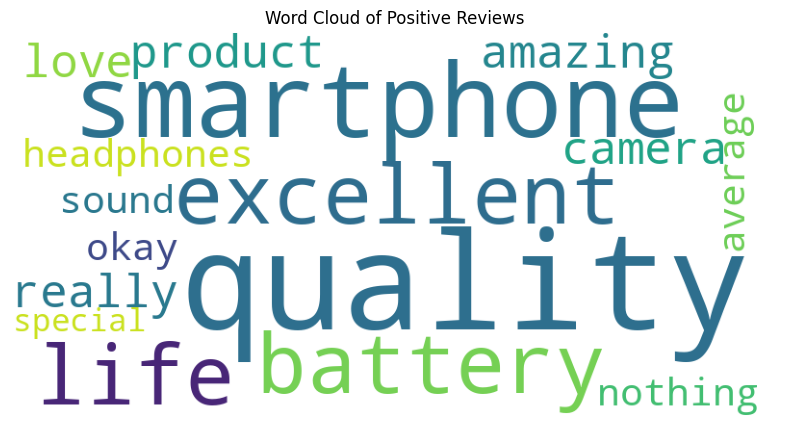

In [19]:
#Q5

reviews = [
    "This smartphone has excellent battery life and amazing camera quality. I really love this product.",

    "The laptop performance is very poor. It is slow and the battery drains quickly.",

    "The headphones are average. The sound quality is okay but nothing special."
]


#1. Sentiment Analysis


positive_reviews = []

for review in reviews:

    analysis = TextBlob(review)

    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity


    # 2.Classify reviews into Posi5ve / Nega5ve / Neutral.
    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)

    elif polarity < 0:
        sentiment = "Negative"

    else:
        sentiment = "Neutral"


    print("Review:")
    print(review)

    print("Polarity:", polarity)
    print("Subjectivity:", subjectivity)
    print("Sentiment:", sentiment)

    print("-" * 50)




# 3.Create a word cloud using the wordcloud library for all posi5ve reviews.


positive_text = " ".join(positive_reviews)


wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(positive_text)


plt.figure(figsize=(10,5))
plt.imshow(wordcloud)
plt.axis("off")
plt.title("Word Cloud of Positive Reviews")
plt.show()


In [24]:
#Q6

text = """
Artificial intelligence is changing the world with new technologies.
Machine learning helps computers learn from data and make decisions.
Deep learning uses neural networks to solve complex problems.
AI applications are used in healthcare, education, and robotics.
Technology continues to improve every day.
Researchers are developing smarter systems that can help humans.
The future of artificial intelligence is full of possibilities.
Artificial intelligence and machine learning are important technologies.
They help people solve difficult problems using computers.
"""

tokenizer = Tokenizer()


#1.Tokenize text using Tokenizer() from keras.preprocessing.text

tokenizer.fit_on_texts([text])




total_words = len(tokenizer.word_index) + 1


print("Word Index:")
print(tokenizer.word_index)

print("\nTotal Words:", total_words)




# 2.Create input sequences and build a simple LSTM or Dense model



input_sequences = []




for sentence in text.split("."):

    token_list = tokenizer.texts_to_sequences([sentence])[0]




    for i in range(1, len(token_list)):

        n_gram_sequence = token_list[:i+1]

        input_sequences.append(n_gram_sequence)



print("\nExample Input Sequences:")
print(input_sequences[:10])








max_sequence_length = max(
    [len(seq) for seq in input_sequences]
)


input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_length,
    padding='pre'
)


print("\nPadded Sequences:")
print(input_sequences)





X = input_sequences[:, :-1]

y = input_sequences[:, -1]


print("\nInput Shape:", X.shape)
print("Output Shape:", y.shape)






model = Sequential()




model.add(
    Embedding(
        input_dim=total_words,
        output_dim=50,
        input_length=X.shape[1]
    )
)




model.add(
    LSTM(100)
)




model.add(
    Dense(
        total_words,
        activation='softmax'
    )
)




model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)




model.summary()



# 3.Train the model and generate 2–3 new lines of text star5ng from any seed word you
#provide.



model.fit(
    X,
    y,
    epochs=100,
    verbose=1
)






def generate_text(seed_text, next_words):

    result = seed_text


    for _ in range(next_words):




        token_list = tokenizer.texts_to_sequences([result])[0]




        token_list = pad_sequences(
            [token_list],
            maxlen=X.shape[1],
            padding='pre'
        )




        predicted = np.argmax(
            model.predict(token_list, verbose=0)
        )


        output_word = ""




        for word, index in tokenizer.word_index.items():

            if index == predicted:
                output_word = word
                break


        result += " " + output_word


    return result





print("\nGenerated Text:")

print(
    generate_text(
        "artificial",
        5
    )
)

Word Index:
{'artificial': 1, 'intelligence': 2, 'learning': 3, 'and': 4, 'are': 5, 'is': 6, 'the': 7, 'technologies': 8, 'machine': 9, 'computers': 10, 'to': 11, 'solve': 12, 'problems': 13, 'help': 14, 'of': 15, 'changing': 16, 'world': 17, 'with': 18, 'new': 19, 'helps': 20, 'learn': 21, 'from': 22, 'data': 23, 'make': 24, 'decisions': 25, 'deep': 26, 'uses': 27, 'neural': 28, 'networks': 29, 'complex': 30, 'ai': 31, 'applications': 32, 'used': 33, 'in': 34, 'healthcare': 35, 'education': 36, 'robotics': 37, 'technology': 38, 'continues': 39, 'improve': 40, 'every': 41, 'day': 42, 'researchers': 43, 'developing': 44, 'smarter': 45, 'systems': 46, 'that': 47, 'can': 48, 'humans': 49, 'future': 50, 'full': 51, 'possibilities': 52, 'important': 53, 'they': 54, 'people': 55, 'difficult': 56, 'using': 57}

Total Words: 58

Example Input Sequences:
[[1, 2], [1, 2, 6], [1, 2, 6, 16], [1, 2, 6, 16, 7], [1, 2, 6, 16, 7, 17], [1, 2, 6, 16, 7, 17, 18], [1, 2, 6, 16, 7, 17, 18, 19], [1, 2, 6, 1

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.0147 - loss: 4.0607  
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.0588 - loss: 4.0519
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1029 - loss: 4.0457
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1176 - loss: 4.0388
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1324 - loss: 4.0305
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1471 - loss: 4.0200
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1324 - loss: 4.0051
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1176 - loss: 3.9858
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0882 - loss: 3.9580
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0882 - loss: 3.9127
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0441 - loss: 3.8628
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0441 - 